# 01 · Convexity and Newton's Method

**Thesis reference:** Chapter 1, Section 1.1 (*Minimum Problems: Convexity and Newton's Method*).

This notebook illustrates three ideas from the thesis:

1. **The second-derivative (Hessian) test**: a function is convex when its Hessian is positive semidefinite, and then every local minimum is global.
2. **Convexity prevents two local minima**: on a non-convex function, gradient descent ends in different minima depending on where it starts.
3. **Newton's method** converges quadratically near the minimum, while gradient descent converges only linearly. We compare them on the Rosenbrock function.

We also draw the unit balls of the $\ell^1$, $\ell^2$ and $\ell^\infty$ norms (Section 1.1.3).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

FIG = Path("..") / "figures"
FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
rng = np.random.default_rng(0)

## 1. The Hessian test for convexity

For $f(x) = \tfrac12 x^T S x$ the Hessian is $S$ itself. If all eigenvalues of $S$ are positive, $f$ is strictly convex with a unique minimum at $x=0$.
If $S$ has a negative eigenvalue, $x=0$ is a **saddle point**.

convex  eigenvalues of S: [1.38196601 3.61803399]
saddle  eigenvalues of S: [-1.  2.]


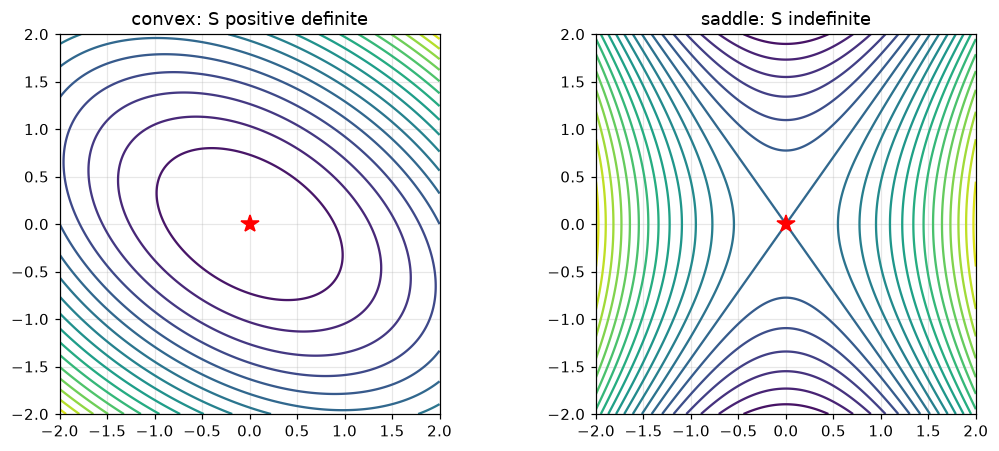

In [2]:
S_convex = np.array([[2.0, 1.0], [1.0, 3.0]])
S_saddle = np.array([[2.0, 0.0], [0.0, -1.0]])

for name, S in [("convex", S_convex), ("saddle", S_saddle)]:
    print(f"{name:7s} eigenvalues of S: {np.linalg.eigvalsh(S)}")

g = np.linspace(-2, 2, 200)
X, Y = np.meshgrid(g, g)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, (name, S) in zip(axes, [("convex: S positive definite", S_convex),
                                ("saddle: S indefinite", S_saddle)]):
    Z = 0.5 * (S[0, 0] * X**2 + 2 * S[0, 1] * X * Y + S[1, 1] * Y**2)
    cs = ax.contour(X, Y, Z, levels=20, cmap="viridis")
    ax.plot(0, 0, "r*", ms=12)
    ax.set_title(name)
    ax.set_aspect("equal")
plt.tight_layout()
plt.show()

## 2. Convexity prevents two local minima

$f(x) = x^4 - 3x^2 + x$ is **not** convex because $f''(x) = 12x^2 - 6$ is negative near $x = 0$.
Gradient descent from different starting points ends in two different minima, and only one of them is the global minimum.

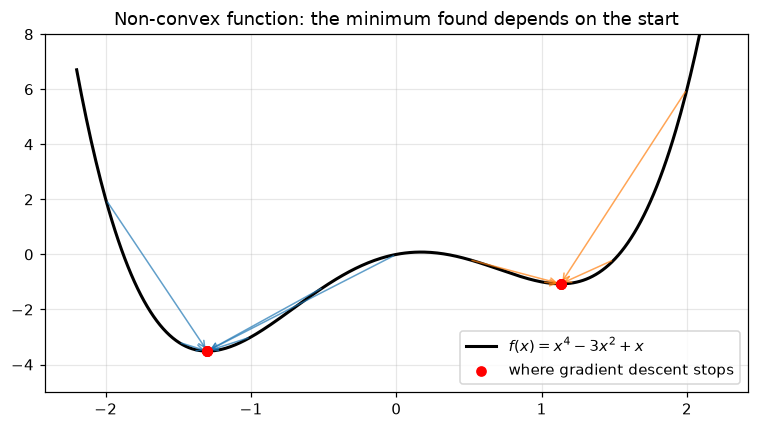

distinct minima found: [np.float64(-1.3008), np.float64(1.1309)]


In [3]:
f1 = lambda x: x**4 - 3 * x**2 + x
df1 = lambda x: 4 * x**3 - 6 * x + 1

starts = np.linspace(-2, 2, 9)
ends = []
for x in starts:
    for _ in range(500):
        x = x - 0.01 * df1(x)
    ends.append(x)

xs = np.linspace(-2.2, 2.2, 400)
plt.figure(figsize=(7, 4))
plt.plot(xs, f1(xs), "k", lw=2, label=r"$f(x)=x^4-3x^2+x$")
for s, e in zip(starts, ends):
    plt.annotate("", xy=(e, f1(e)), xytext=(s, f1(s)),
                 arrowprops=dict(arrowstyle="->", color="tab:blue" if e < 0 else "tab:orange", alpha=0.7))
plt.scatter(ends, f1(np.array(ends)), c="red", zorder=3, label="where gradient descent stops")
plt.ylim(-5, 8)
plt.legend()
plt.title("Non-convex function: the minimum found depends on the start")
plt.tight_layout()
plt.show()
print("distinct minima found:", sorted(set(np.round(ends, 4))))

## 3. Newton's method vs gradient descent on the Rosenbrock function

$$f(x, y) = (1-x)^2 + 100\,(y - x^2)^2,$$
with minimum $f = 0$ at $(1, 1)$. Its curved, narrow valley is a classic hard case for gradient descent.

* **Gradient descent:** $x_{k+1} = x_k - s_k \nabla f(x_k)$
* **Newton:** $x_{k+1} = x_k - s_k H(x_k)^{-1} \nabla f(x_k)$

Both use a backtracking (Armijo) line search to choose $s_k$.

In [4]:
def rosen(x):
    return (1 - x[0])**2 + 100 * (x[1] - x[0]**2)**2

def rosen_grad(x):
    return np.array([-2 * (1 - x[0]) - 400 * x[0] * (x[1] - x[0]**2),
                     200 * (x[1] - x[0]**2)])

def rosen_hess(x):
    return np.array([[2 - 400 * (x[1] - 3 * x[0]**2), -400 * x[0]],
                     [-400 * x[0], 200.0]])

def backtracking(f, g, x, d, t=1.0, beta=0.5, c=1e-4):
    fx, slope = f(x), g(x) @ d
    while f(x + t * d) > fx + c * t * slope:
        t *= beta
    return t

def descend(direction, x0, iters, tol=1e-10):
    x = np.array(x0, float)
    path = [x.copy()]
    for _ in range(iters):
        d = direction(x)
        if rosen_grad(x) @ d >= 0:          # not a descent direction: fall back to -grad
            d = -rosen_grad(x)
        x = x + backtracking(rosen, rosen_grad, x, d) * d
        path.append(x.copy())
        if np.linalg.norm(rosen_grad(x)) < tol:
            break
    return np.array(path)

x0 = [-1.2, 1.0]
gd_path = descend(lambda x: -rosen_grad(x), x0, iters=20000)
nt_path = descend(lambda x: -np.linalg.solve(rosen_hess(x), rosen_grad(x)), x0, iters=100)

print(f"Gradient descent: {len(gd_path)-1:6d} iterations, final x = {gd_path[-1]}, f = {rosen(gd_path[-1]):.2e}")
print(f"Newton's method : {len(nt_path)-1:6d} iterations, final x = {nt_path[-1]}, f = {rosen(nt_path[-1]):.2e}")

Gradient descent:  20000 iterations, final x = [1.         0.99999999], f = 2.44e-17
Newton's method :     22 iterations, final x = [1. 1.], f = 0.00e+00


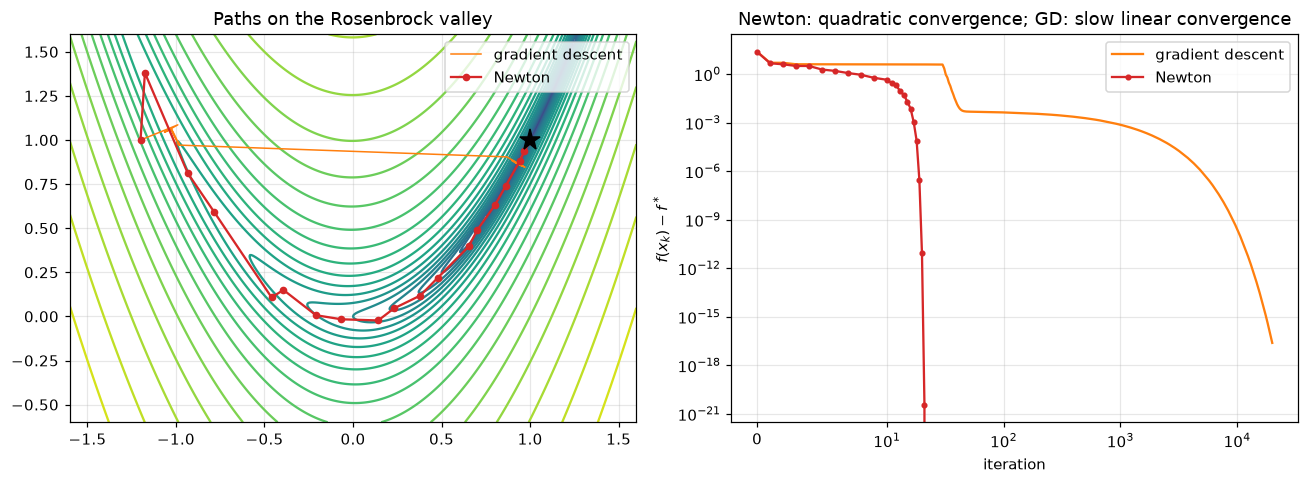

In [5]:
gx = np.linspace(-1.6, 1.6, 400)
gy = np.linspace(-0.6, 1.6, 400)
X, Y = np.meshgrid(gx, gy)
Z = (1 - X)**2 + 100 * (Y - X**2)**2

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ax = axes[0]
ax.contour(X, Y, np.log10(Z + 1e-3), levels=30, cmap="viridis")
ax.plot(gd_path[:, 0], gd_path[:, 1], "-", color="tab:orange", lw=1, label="gradient descent")
ax.plot(nt_path[:, 0], nt_path[:, 1], "o-", color="tab:red", ms=4, label="Newton")
ax.plot(1, 1, "k*", ms=14)
ax.set_title("Paths on the Rosenbrock valley")
ax.legend()

ax = axes[1]
ax.semilogy([rosen(p) for p in gd_path], color="tab:orange", label="gradient descent")
ax.semilogy([rosen(p) for p in nt_path], "o-", color="tab:red", ms=3, label="Newton")
ax.set_xscale("symlog", linthresh=10)
ax.set_xlabel("iteration")
ax.set_ylabel(r"$f(x_k) - f^*$")
ax.set_title("Newton: quadratic convergence; GD: slow linear convergence")
ax.legend()
plt.tight_layout()
plt.savefig(FIG / "01_newton_vs_gd_rosenbrock.png", bbox_inches="tight")
plt.show()

**Quadratic convergence.** Near the solution, Newton's error is roughly squared at each step, so the number of correct digits doubles:

In [6]:
err = np.linalg.norm(nt_path - np.array([1.0, 1.0]), axis=1)
for k in range(max(0, len(err) - 7), len(err)):
    print(f"k = {k:2d}   ||x_k - x*|| = {err[k]:.3e}")

k = 16   ||x_k - x*|| = 1.320e-01
k = 17   ||x_k - x*|| = 7.126e-02
k = 18   ||x_k - x*|| = 9.180e-03
k = 19   ||x_k - x*|| = 1.173e-03
k = 20   ||x_k - x*|| = 2.727e-06
k = 21   ||x_k - x*|| = 1.351e-10
k = 22   ||x_k - x*|| = 0.000e+00


## 4. The $\ell^1$, $\ell^2$ and $\ell^\infty$ unit balls

The thesis (Section 1.1.3) uses three norms. Their unit balls $\{x : \|x\| \le 1\}$ are a diamond, a circle and a square.
All three are convex sets, because every norm is a convex function.
The corners of the $\ell^1$ ball are why $\ell^1$ penalties (LASSO) give **sparse** solutions.

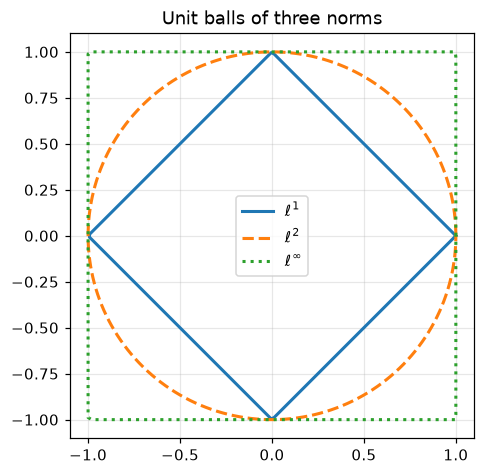

In [7]:
t = np.linspace(0, 2 * np.pi, 400)
u = np.c_[np.cos(t), np.sin(t)]
plt.figure(figsize=(4.5, 4.5))
for p, style in [(1, "-"), (2, "--"), (np.inf, ":")]:
    r = u / np.linalg.norm(u, ord=p, axis=1, keepdims=True)
    plt.plot(r[:, 0], r[:, 1], style, lw=2, label=rf"$\ell^{{{'∞' if p == np.inf else p}}}$")
plt.gca().set_aspect("equal")
plt.legend()
plt.title("Unit balls of three norms")
plt.tight_layout()
plt.savefig(FIG / "01_norm_balls.png", bbox_inches="tight")
plt.show()

### Takeaways
* Positive definite Hessian ⇒ convex ⇒ a single minimum that any descent method finds.
* On non-convex problems, like deep-network training, the result depends on initialization.
* Newton's method uses curvature (the Hessian) and converges in a handful of steps, but each step needs a linear solve with the $n\times n$ Hessian. That cost is why first-order methods (notebooks 03–04) dominate in machine learning.